# Практическая работа № 2. Численные методы решения нелинейных уравнений

Вариант: 9

**Цель:** отделить действительные корни уравнения и уточнить положительный корень несколькими методами с заданной точностью.

**Вариант 9.** $F(x)=\sin x-0{,}2x=0$.

Так как $|\sin x|\le 1$, действительные корни лежат внутри $[-5;5]$. Уравнение нечётное, поэтому вместе с положительным корнем существует симметричный отрицательный; $x=0$ — точный корень.

Далее для уточнения используется отрезок $[2{,}5;2{,}6]$.

In [1]:
import math

def F(x):
    """Левая часть уравнения F(x) = 0."""
    return math.sin(x) - 0.2 * x

def dF(x):
    """Первая производная F'(x)."""
    return math.cos(x) - 0.2

def d2F(x):
    """Вторая производная F''(x)."""
    return -math.sin(x)

A, B = 2.5, 2.6

## Задание 1. Отделение корней

Табулирование функции и построение графиков $y=\sin x$ и $y=0{,}2x$. Если функция непрерывна и $F(a)F(b)<0$, на отрезке $[a;b]$ есть корень.

Табулирование F(x) = sin x - 0,2x на [-5; 5], шаг 0,5
     x |       F(x)
 -5.00 |    1.95892
 -4.50 |    1.87753
 -4.00 |    1.55680
 -3.50 |    1.05078
 -3.00 |    0.45888
 -2.50 |   -0.09847
 -2.00 |   -0.50930
 -1.50 |   -0.69749
 -1.00 |   -0.64147
 -0.50 |   -0.37943
  0.00 |    0.00000
  0.50 |    0.37943
  1.00 |    0.64147
  1.50 |    0.69749
  2.00 |    0.50930
  2.50 |    0.09847
  3.00 |   -0.45888
  3.50 |   -1.05078
  4.00 |   -1.55680
  4.50 |   -1.87753
  5.00 |   -1.95892
Точные корни в узлах: [0.0]
Отрезки смены знака: [(-3.0, -2.5), (2.5, 3.0)]

Уточнение отрезка для положительного корня, шаг 0,1:
     x |       F(x)
  2.00 |    0.50930
  2.10 |    0.44321
  2.20 |    0.36850
  2.30 |    0.28571
  2.40 |    0.19546
  2.50 |    0.09847
  2.60 |   -0.00450
  2.70 |   -0.11262
  2.80 |   -0.22501
  2.90 |   -0.34075
  3.00 |   -0.45888
Отрезок отделения: [(2.5, 2.6)]
График сохранён: graph_separation.png


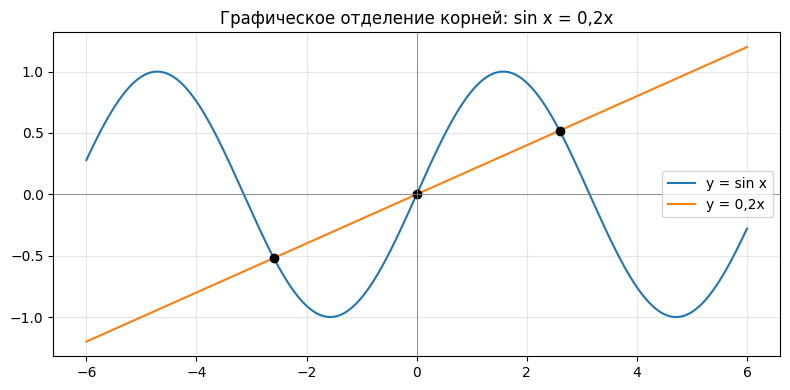

In [2]:
import os

import matplotlib

import matplotlib.pyplot as plt

import numpy as np

def tabulate(a, b, h):
    """Табулирует F(x) на [a; b] с шагом h и возвращает отрезки смены знака."""
    n = round((b - a) / h)
    xs = [round(a + i * h, 10) for i in range(n + 1)]
    segments, exact = [], []
    print(f"{'x':>6} | {'F(x)':>10}")
    for i, x in enumerate(xs):
        fx = F(x)
        print(f"{x:6.2f} | {fx:10.5f}")
        if abs(fx) < 1e-12:
            exact.append(x)
        elif i > 0 and F(xs[i - 1]) * fx < 0 and abs(F(xs[i - 1])) > 1e-12:
            segments.append((xs[i - 1], x))
    return segments, exact

def plot(path):
    x = np.linspace(-6, 6, 600)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(x, np.sin(x), label="y = sin x")
    ax.plot(x, 0.2 * x, label="y = 0,2x")
    for r in (-2.5957, 0.0, 2.5957):
        ax.plot(r, np.sin(r), "ko")
    ax.axhline(0, color="gray", lw=0.6)
    ax.axvline(0, color="gray", lw=0.6)
    ax.grid(alpha=0.3)
    ax.legend()
    ax.set_title("Графическое отделение корней: sin x = 0,2x")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    print(f"График сохранён: {path}")

print("Табулирование F(x) = sin x - 0,2x на [-5; 5], шаг 0,5")
segments, exact = tabulate(-5, 5, 0.5)
print("Точные корни в узлах:", exact)
print("Отрезки смены знака:", segments)
print("\nУточнение отрезка для положительного корня, шаг 0,1:")
seg2, _ = tabulate(2.0, 3.0, 0.1)
print("Отрезок отделения:", seg2)
plot(os.path.join(os.getcwd(), "graph_separation.png"))

## Задание 2. Метод половинного деления

На каждом шаге берём $m=(a+b)/2$ и оставляем половину, на концах которой значения функции имеют разные знаки. Остановка при $(b-a)/2\le 10^{-3}$.

In [3]:
def bisection(a, b, eps):
    n = 0
    print(f"{'n':>2} | {'a':>9} | {'b':>9} | {'x=(a+b)/2':>9} | {'F(a)':>9} | {'F(x)':>9} | {'(b-a)/2':>8}")
    while (b - a) / 2 > eps:
        x = (a + b) / 2
        print(f"{n:2d} | {a:9.5f} | {b:9.5f} | {x:9.5f} | {F(a):9.5f} | {F(x):9.5f} | {(b - a) / 2:8.5f}")
        if F(a) * F(x) <= 0:
            b = x
        else:
            a = x
        n += 1
    x = (a + b) / 2
    return x, (b - a) / 2, n

eps = 1e-3
x, err, n = bisection(A, B, eps)
print(f"\nКорень x = {x:.6f} ± {err:.6f}, шагов деления: {n}")
print(f"С точностью 1e-3: x = {x:.3f}")

 n |         a |         b | x=(a+b)/2 |      F(a) |      F(x) |  (b-a)/2
 0 |   2.50000 |   2.60000 |   2.55000 |   0.09847 |   0.04768 |  0.05000
 1 |   2.55000 |   2.60000 |   2.57500 |   0.04768 |   0.02176 |  0.02500
 2 |   2.57500 |   2.60000 |   2.58750 |   0.02176 |   0.00867 |  0.01250
 3 |   2.58750 |   2.60000 |   2.59375 |   0.00867 |   0.00210 |  0.00625
 4 |   2.59375 |   2.60000 |   2.59687 |   0.00210 |  -0.00120 |  0.00313
 5 |   2.59375 |   2.59687 |   2.59531 |   0.00210 |   0.00045 |  0.00156

Корень x = 2.596094 ± 0.000781, шагов деления: 6
С точностью 1e-3: x = 2.596


## Задание 3. Метод простой итерации

Преобразование $x=\varphi(x)$, где $\varphi(x)=x+F(x)/M$. На выбранном отрезке коэффициент сжатия $q<1$; точность $10^{-6}$.

In [4]:
m = min(abs(dF(A)), abs(dF(B)))

M = max(abs(dF(A)), abs(dF(B)))

LAM = 1 / M

q = 1 - m / M

def phi(x):
    return x + LAM * F(x)

def iterate(x0, eps):
    stop = eps * (1 - q) / q
    print(f"m = {m:.5f}, M = {M:.5f}, lambda = 1/M = {LAM:.5f}, q = {q:.5f}")
    print(f"Порог остановки eps*(1-q)/q = {stop:.3e}")
    x_prev, n = x0, 0
    print(f"{'n':>2} | {'x_n':>12} | {'|x_n - x_n-1|':>14}")
    print(f"{n:2d} | {x_prev:12.8f} |")
    while True:
        x = phi(x_prev)
        n += 1
        d = abs(x - x_prev)
        print(f"{n:2d} | {x:12.8f} | {d:14.3e}")
        if d <= stop:
            return x, n
        x_prev = x

x, n = iterate((A + B) / 2, 1e-6)
print(f"\nКорень x = {x:.6f} (итераций: {n}), F(x) = {F(x):.2e}")

m = 1.00114, M = 1.05689, lambda = 1/M = 0.94617, q = 0.05274
Порог остановки eps*(1-q)/q = 1.796e-05
 n |          x_n |  |x_n - x_n-1|
 0 |   2.55000000 |
 1 |   2.59511706 |      4.512e-02
 2 |   2.59573769 |      6.206e-04
 3 |   2.59573908 |      1.389e-06

Корень x = 2.595739 (итераций: 3), F(x) = 3.06e-09


## Задание 4. Комбинированный метод хорд и касательных

Метод Ньютона и метод хорд уточняют корень с разных сторон. Погрешность оценивается половиной расстояния между полученными приближениями.

In [5]:
def combined(a, b, eps):
    if F(a) * d2F(a) > 0:
        c = a
        xt, xc = a, b
    else:
        c = b
        xt, xc = b, a
    print(f"c = {c} (F(c)*F''(c) > 0): касательные от {xt}, хорды от {xc}")
    n = 0
    print(f"{'n':>2} | {'хорды':>12} | {'касательные':>12} | {'полуразность':>12}")
    while True:
        xt = xt - F(xt) / dF(xt)
        xc = (c * F(xc) - xc * F(c)) / (F(xc) - F(c))
        n += 1
        half = abs(xt - xc) / 2
        print(f"{n:2d} | {xc:12.8f} | {xt:12.8f} | {half:12.3e}")
        if half <= eps:
            return (xt + xc) / 2, half, n

x, err, n = combined(A, B, 1e-6)
print(f"\nКорень x = {x:.6f} ± {err:.1e} (итераций: {n}), F(x) = {F(x):.2e}")

c = 2.6 (F(c)*F''(c) > 0): касательные от 2.6, хорды от 2.5
 n |        хорды |  касательные | полуразность
 1 |   2.59563116 |   2.59574352 |    5.618e-05
 2 |   2.59573897 |   2.59573908 |    5.640e-08

Корень x = 2.595739 ± 5.6e-08 (итераций: 2), F(x) = 5.95e-08


## Задание 5. Инструментальная проверка

Сравнение полученных результатов с функциями `scipy.optimize.brentq` и `fsolve`.

In [6]:
from scipy.optimize import brentq, fsolve

import contextlib, io

x_brent = brentq(F, A, B, xtol=1e-12)
x_fsolve = fsolve(lambda v: [F(v[0])], [2.55], xtol=1e-12)[0]
with contextlib.redirect_stdout(io.StringIO()):
    x_bis, _, _ = bisection(A, B, 1e-3)
    x_it, _ = iterate((A + B) / 2, 1e-6)
    x_ct, _, _ = combined(A, B, 1e-6)
print(f"scipy.optimize.brentq : {x_brent:.6f}")
print(f"scipy.optimize.fsolve : {x_fsolve:.6f}")
print("Сопоставление:")
print(f"  половинное деление (1e-3)  : {x_bis:.6f}  отклонение {abs(x_bis - x_brent):.1e}")
print(f"  простая итерация (1e-6)    : {x_it:.6f}  отклонение {abs(x_it - x_brent):.1e}")
print(f"  хорды и касательные (1e-6) : {x_ct:.6f}  отклонение {abs(x_ct - x_brent):.1e}")

scipy.optimize.brentq : 2.595739
scipy.optimize.fsolve : 2.595739
Сопоставление:
  половинное деление (1e-3)  : 2.596094  отклонение 3.5e-04
  простая итерация (1e-6)    : 2.595739  отклонение 2.9e-09
  хорды и касательные (1e-6) : 2.595739  отклонение 5.6e-08


**Вывод.** Действительные корни: $x_1\approx-2{,}595739$, $x_2=0$, $x_3\approx 2{,}595739$. Метод половинного деления находит положительный корень с точностью $10^{-3}$, остальные методы — с точностью $10^{-6}$ (в пределах данных условий).